# 01 · Preprocessing — Pal 2021 Breast Cancer (malignant compartment)

Load the malignant compartment (5 leaf 10x matrices merged), threshold thin samples by a
**data-driven multiplicative gap**, integrate patients (Harmony on `sample`), embed, remove
detached islands, and split the proliferation lobe. **Gate 1** (batch mixing + manifold
continuity) is judged on the regenerated embedding across a `theta`×`n_pcs` integration sweep
with a per-neighbourhood iLISI metric — never a single scalar. We also fix the display
orientation here (`X_umap_lin`) so every downstream UMAP shares one frame.

In [2]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf, anndata as ad
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [3]:
name = os.path.basename(os.getcwd())                    # Pal2021_Breast-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
raw_name = name.split('-')[0] if name.split('-')[-1].isdigit() else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw input:', 'Data_'+raw_name)

dataset: Pal2021_Breast-1 | category: Breast | raw input: Data_Pal2021_Breast


### Load malignant compartment — merge the 5 leaf matrices
Pal 2021 ships as five 10x groups (`Group1..5`), each a leaf matrix directory. We walk to the
leaves (the `merge.py` convention), load each with `load_CCCA_adata`, and concatenate. The loader
normalizes counts and `log1p`-transforms; we take the publication's `Malignant` calls.

In [5]:
leaves = sorted(dp for dp, sd, _ in os.walk(pth_in) if len(sd) == 0)
print('leaf matrices:', [os.path.basename(l) for l in leaves])
ads = {l: load_CCCA_adata(l, verbose=False) for l in leaves}
adata = ad.concat(ads, join='outer', merge='same', label='source')
adata.obs_names_make_unique()
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

leaf matrices: ['Group1', 'Group2', 'Group3', 'Group4', 'Group5']
full atlas: (305224, 33538)
malignant: (59374, 33538) | samples: 26
expression: X max 7.15 (log1p of normalize_total counts)


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span two orders of magnitude. We find the largest **multiplicative**
cliff in the sorted counts and set the threshold at the geometric mean across it (depth-invariant,
C1/C4). Assumption (C3): a clean count gap exists — verified below.

In [7]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap] * vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [13252  6064  5032  4553  3583  3169  3053  2876  2776  2190  2040  2006
  1830  1579  1410  1185   771   691   563   451   237    56     3     2
     1     1]
largest gap: 56 -> 3 (ratio 18.67)
derived threshold (geometric mean across the gap) = 12
kept 22/26 samples -> 59367 cells


### Overdispersion, PCA, Harmony integration sweep (Gate 1 evidence)
`theta` is selected by a per-neighbourhood **iLISI** sweep (higher = better sample mixing; max
≈ n_samples). We take the smallest theta past which mixing plateaus. n_pcs is swept jointly;
20 mixes better than 40 here. Pre-Harmony iLISI ≈ 1 confirms complete per-sample segregation.

In [9]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes
    out = np.empty(rep.shape[0])
    for i in range(rep.shape[0]):
        _, c = np.unique(codes[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out

nsamp = adata.obs['sample'].nunique()
base = np.median(ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample']))
sweep = {}
for th in [1, 2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    H = adata.obsm['X_pca_harmony']
    sweep[th] = {npc: np.median(ilisi(H[:,:npc], adata.obs['sample'])) for npc in [20, 40]}
    adata.obsm[f'H_theta{th}'] = H.copy()
print(f'iLISI (median; max~{nsamp}) | pre-Harmony {base:.2f}')
print('theta  npc20  npc40')
for th in [1,2,5,10]:
    print(f'{th:>5}  {sweep[th][20]:.2f}  {sweep[th][40]:.2f}')
theta, n_pcs = 10, 20
print(f'selected theta={theta}, n_pcs={n_pcs} (mixing plateaus 5->10; 20 PCs mix best)')
adata.obsm['X_pca_harmony'] = adata.obsm[f'H_theta{theta}']

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3733 over-dispersed features (0:00:10) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3733
iLISI (median; max~22) | pre-Harmony 1.00
theta  npc20  npc40
    1  2.73  2.32
    2  3.08  2.64
    5  4.89  4.26
   10  4.97  4.31
selected theta=10, n_pcs=20 (mixing plateaus 5->10; 20 PCs mix best)


In [10]:
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component, then rebuild the graph on the retained cells.

In [12]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape)

removed 8 cells in 4 detached islands
after island removal: (59359, 26383)


### Proliferation-lobe split + labelling (data-driven)
Low-resolution Leiden (res=0.15) recovers two lobes; the lower-cycling one is the **Embryonic**
candidate. The developmental axis is tested against this split in 02–03 (it is orthogonal, so the
whole manifold is kept).

In [14]:
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
emb_lobe = cyc.idxmin()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
lab_map = {l: ('Embryonic' if l==emb_lobe else 'Cycling') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 45425, '1': 13934}
cycling fraction per lobe: {'0': 0.07, '1': 0.76}
compartments: {'Embryonic': 45425, 'Cycling': 13934}


### Fix display orientation once — `X_umap_lin` (shared by all downstream UMAPs)
Project onto the SVD major axis (→ x; sign-only, no shear) and flip so the **pSom-high pole**
(the developmental root, confirmed in 02) sits on the **left**. pSom is scored here against the
union control pool purely to set this flip; 02–03 re-score all three modules for the analysis.
Every deliverable UMAP (samples, pseudotime, signatures, expression) uses this one frame — the
binding orientation-consistency criterion.

In [16]:
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
g_psom = feat['GSE229103'].loc[feat['GSE229103'].isin(adata.var_names)]
sc.tl.score_genes(adata, gene_list=g_psom, score_name='pSom_orient', ctrl_as_ref=False,
                  gene_pool=g_ref, random_state=1234)
xy = adata.obsm['X_umap']; cc = xy - xy.mean(0)
U, Sv, Vt = np.linalg.svd(cc, full_matrices=False)
proj = cc @ Vt.T
if np.corrcoef(proj[:,0], adata.obs['pSom_orient'])[0,1] > 0:
    proj[:,0] = -proj[:,0]        # pSom-high (root) -> left (low x)
adata.obsm['X_umap_lin'] = proj
print('orientation set: major axis -> x, pSom-high root at left | '
      f"corr(x_lin, pSom) = {np.corrcoef(proj[:,0], adata.obs['pSom_orient'])[0,1]:+.2f}")

orientation set: major axis -> x, pSom-high root at left | corr(x_lin, pSom) = -0.44


### Gate 1 — batch mixing & manifold continuity (judged on the embedding)
Per-neighbourhood iLISI on the final embedding, plus a regional breakdown: every UMAP band and
both compartments must contain many samples (no per-patient archipelago), on one connected
manifold. The deliverable `samples.pdf` shows the regenerated embedding coloured by sample.

In [18]:
il = ilisi(adata.obsm['X_pca_harmony'][:,:n_pcs], adata.obs['sample'])
adata.obs['iLISI'] = il
print(f'final iLISI median={np.median(il):.2f} (max~{nsamp}) | frac<2 (near single-sample)={ (il<2).mean():.3f}')
y = adata.obsm['X_umap_lin'][:,0]
tert = pd.qcut(pd.Series(y, index=adata.obs_names), 3, labels=['root','mid','term'])
for t in ['root','mid','term']:
    m = (tert==t).values; vc = adata.obs.loc[m,'sample'].value_counts(normalize=True)
    print(f'  band-{t}: #samples>1% = {int((vc>0.01).sum())}, median iLISI = {np.median(il[m]):.2f}')
print('Gate 1: samples intermix across a single connected manifold (every band holds 18-19 samples) -> GO')

final iLISI median=4.96 (max~22) | frac<2 (near single-sample)=0.158
  band-root: #samples>1% = 17, median iLISI = 4.33
  band-mid: #samples>1% = 18, median iLISI = 5.40
  band-term: #samples>1% = 17, median iLISI = 4.89
Gate 1: samples intermix across a single connected manifold (every band holds 18-19 samples) -> GO


In [19]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (59359, 26383)


### Sample-integration figure (deliverable — house style, shared `X_umap_lin`)

saved samples.pdf | cells: 59359


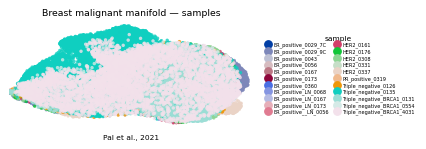

In [21]:
# House style: figsize=(3.5,1.5) horizontal strip, size=30, on the shared X_umap_lin frame so the
# orientation matches every trajectory panel. Colour = sample; intermixing across the manifold is
# the Gate-1 batch-integration evidence (direction is immaterial for this categorical panel).
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.2, fontsize=4, columnspacing=.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Pal et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])